### Transformer Network Implementation using Tensor Flow

In [1]:
#load important modules
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Embedding, MultiHeadAttention, Dense, Input, Dropout, LayerNormalization

#### Postional Encoding
##### In RNNs, words are ingested into the neural network sequentially, so it is easy to know the postion of the tokens in the sequence. The transformer ingest the entire sequence to the network to get the attention based representation. While the parallel computing of the representation is achieved, it is not possible to know where in the sentence a word is located. So postional encoding helps this.

In [2]:
def position_enc(emb_dim, len_seq):
    '''emb_dim -- embedding dimension (integer)
       len_seq -- maximum len of the sequence (integer)
    '''
    position = np.arange(len_seq)[:, np.newaxis]
    emb_k = np.arange(emb_dim)[np.newaxis, :]
    emb_i = emb_k // 2
    angles = position / (10000**((2*emb_i)/emb_dim))
    #angles are in rad, now we apply sine for even indices and cos for odd indices horizontally
    angles[:, 0::2] = np.sin(angles[:, 0::2])
    angles[:, 1::2] = np.cos(angles[:, 1::2])
    pos_encodings = angles[np.newaxis, ...]
    return tf.cast(pos_encodings, dtype=tf.float32)

In [3]:
position_enc(10, 8)

<tf.Tensor: shape=(1, 8, 10), dtype=float32, numpy=
array([[[ 0.0000000e+00,  1.0000000e+00,  0.0000000e+00,  1.0000000e+00,
          0.0000000e+00,  1.0000000e+00,  0.0000000e+00,  1.0000000e+00,
          0.0000000e+00,  1.0000000e+00],
        [ 8.4147096e-01,  5.4030228e-01,  1.5782665e-01,  9.8746681e-01,
          2.5116222e-02,  9.9968451e-01,  3.9810613e-03,  9.9999207e-01,
          6.3095731e-04,  9.9999982e-01],
        [ 9.0929741e-01, -4.1614684e-01,  3.1169716e-01,  9.5018148e-01,
          5.0216600e-02,  9.9873835e-01,  7.9620592e-03,  9.9996829e-01,
          1.2619144e-03,  9.9999923e-01],
        [ 1.4112000e-01, -9.8999250e-01,  4.5775455e-01,  8.8907862e-01,
          7.5285293e-02,  9.9716204e-01,  1.1942931e-02,  9.9992865e-01,
          1.8928709e-03,  9.9999821e-01],
        [-7.5680250e-01, -6.5364361e-01,  5.9233773e-01,  8.0568975e-01,
          1.0030649e-01,  9.9495661e-01,  1.5923614e-02,  9.9987322e-01,
          2.5238267e-03,  9.9999684e-01],
        

(1, 28, 512)


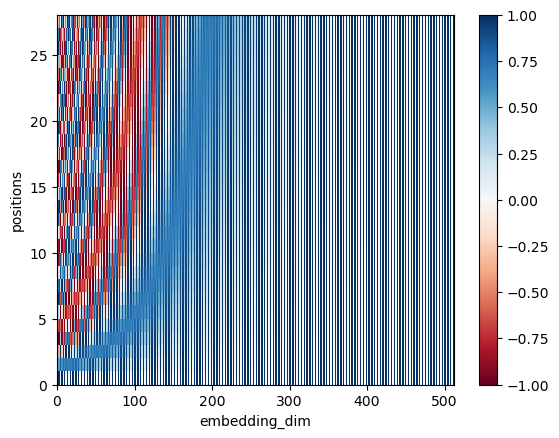

In [4]:
pos_enc = position_enc(512, 28)
print(pos_enc.shape)

plt.pcolormesh(pos_enc[0], cmap='RdBu')
plt.xlabel('embedding_dim')
plt.xlim((0, 512))
plt.ylabel('positions')
plt.colorbar()
plt.show()

###### This adds positional information to the embedding

#### Padding is an important aspect of the transfromer architecture as with sequential models
##### If the maximum length of the sequence to be fed to the transformer is 10, then every long sequences have to be truncated to 10 and short sentences should be pad with zero so that its length fits the architecture. However padding zeros would affect the softmax computation so we do masking to hinder the contribution to the softmax. if the value of the padding is zero, then the numerator np.exp(0) will have contributions to the softmax, so we set these values to small negative numbers like -1.e9

In [34]:
#Assuming the sequence is already padded
def mask_pad(sequences):
    masked_seq = tf.cast(tf.math.equal(sequences, 0), tf.float32)
    masked_seq*=-1.0e9
    #then you add the output of this to the input sequence
    return masked_seq

In [40]:
x = np.array([[2, 1, 3, 0, 0], [1, -1, 0, 0, 1], [3, 2, 1, 4, 0]])

In [44]:
x = tf.cast(x, tf.float32)

In [45]:
tf.keras.activations.softmax(x, axis=-1)

<tf.Tensor: shape=(3, 5), dtype=float32, numpy=
array([[0.2295246 , 0.08443738, 0.6239125 , 0.03106278, 0.03106278],
       [0.34829926, 0.04713718, 0.12813213, 0.12813213, 0.34829926],
       [0.23412165, 0.08612854, 0.03168492, 0.6364086 , 0.01165623]],
      dtype=float32)>

In [46]:
tf.keras.activations.softmax(x+mask_pad(x), axis=-1)

<tf.Tensor: shape=(3, 5), dtype=float32, numpy=
array([[0.24472848, 0.09003057, 0.66524094, 0.        , 0.        ],
       [0.4683105 , 0.06337894, 0.        , 0.        , 0.4683105 ],
       [0.23688284, 0.08714432, 0.0320586 , 0.6439143 , 0.        ]],
      dtype=float32)>

#### Just so you know the softmax is the one on the self attention computation since Q, K, V are zeros for zero input sequences.

#### we have to implement a look-ahead mask helps our model pretend it predicted the correct output given prior predictions without looking the entire sequence, this masking is done in training since in training we have the entire full sequence.
##### If the training output sequence is [10, 20, 30], to predict the second token given the model predicted the first one, the masking would be [10, -1e9, -1e9] and see if the model outputs [10, 20, -1e9].

In [47]:
### Lets skip this implementation for now and we will do it later